# Multi-Class Drone Detection with YOLOv8
### Day, Night, and Hazy Airframe Classification

**Objective.** Train and evaluate a YOLOv8-based object detector capable of distinguishing multiple drone classes under varying environmental conditions, including daytime, nighttime, and hazy scenarios, using the
[Multi-Class Drone Detection Dataset (YOLOv8-Ready)](https://www.kaggle.com/datasets/troykueh/multi-class-drone-detection-dataset-yolov8-ready)

**Notebook structure**
1. Environment Setup and Reproducibility
2. Google Drive Mounting
3. Directory Structure
4. Dataset Discovery and Integrity Checks
5. Exploratory Data Analysis
6. Ground Truth Visualization
7. data.yaml Construction
8. Baseline Training with YOLOv8n
9. Training Curve Analysis
10. Quantitative Evaluation
11. Confusion Matrix, PR Curve, and F1 Curve Analysis
12. Qualitative Inference on Held-Out Test Images
13. Test-Set Metrics and ONNX Export
14. Failure Analysis and Future Improvements

## 1. Environment Setup & Reproducibility

In [1]:
import random
import shutil
import warnings
from pathlib import Path

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import torch

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 110,
})

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"Torch: {torch.__version__} | CUDA available: {torch.cuda.is_available()} | Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Torch: 2.11.0+cu128 | CUDA available: True | Device: 0
GPU: NVIDIA A100-SXM4-80GB


In [2]:
try:
    import ultralytics
except ImportError:
    !pip install -q ultralytics

from ultralytics import YOLO
import ultralytics
ultralytics.checks()

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Setup complete ✅ (12 CPUs, 167.1 GB RAM, 46.7/235.7 GB disk)


## 2. Google Drive Mounting
**One-time setup:** upload your dataset `.zip` to Google Drive via the regular
[drive.google.com](https://drive.google.com) website (VS Code can't do this upload step for
you — it has to go through Drive's own web/desktop client since the file starts out on your
local disk). Once it's in Drive, point `DRIVE_DATASET_ZIP` below at its path and re-run this
cell each new session — the mount + unzip takes well under 2 minutes for ~10k images.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DATASET_ZIP = "/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/dataset.zip"
LOCAL_DATASET_DIR = Path("/content/dataset")
RAW_RUNS_DIR = Path("/content/runs")

Mounted at /content/drive


## 3. Directory Structure

In [4]:
SYNC_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8")
MODELS_DIR = SYNC_ROOT / "models"
RESULTS_DIR = SYNC_ROOT / "results"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Sync root (Google Drive): {SYNC_ROOT}")
print(f"Models dir  : {MODELS_DIR}")
print(f"Results dir : {RESULTS_DIR}")

Sync root (Google Drive): /content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8
Models dir  : /content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models
Results dir : /content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/results


In [5]:
import zipfile

if LOCAL_DATASET_DIR.exists() and any(LOCAL_DATASET_DIR.iterdir()):
    print(f"{LOCAL_DATASET_DIR} already populated — skipping extraction.")
else:
    zip_path = Path(DRIVE_DATASET_ZIP)
    assert zip_path.exists(), (
        f"Zip not found at {zip_path}. Update DRIVE_DATASET_ZIP above to match the exact "
        f"filename/path you uploaded to Drive."
    )
    LOCAL_DATASET_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Extracting {zip_path.name} -> {LOCAL_DATASET_DIR} ...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(LOCAL_DATASET_DIR)
    print("Done.")

print("\nExtracted top-level contents:")
for p in sorted(LOCAL_DATASET_DIR.iterdir()):
    print(" -", p.name)

Extracting dataset.zip -> /content/dataset ...
Done.

Extracted top-level contents:
 - dataset.yaml
 - images
 - labels
 - metadata.csv


## 4. Dataset Discovery & Integrity Checks

In [6]:
CANDIDATE_ROOTS = [
    LOCAL_DATASET_DIR,
    *[p for p in LOCAL_DATASET_DIR.iterdir() if p.is_dir()],
]

def locate_dataset_root(candidates):
    for c in candidates:
        if (c / "images").exists() or (c / "dataset" / "images").exists():
            return c
    raise FileNotFoundError(
        f"Could not find an 'images/' folder under {LOCAL_DATASET_DIR}."
    )

DATASET_ROOT = locate_dataset_root(CANDIDATE_ROOTS)
print(f"Dataset root: {DATASET_ROOT}")
print("\nTop-level contents:")
for p in sorted(DATASET_ROOT.iterdir()):
    print(" -", p.name)

Dataset root: /content/dataset

Top-level contents:
 - dataset.yaml
 - images
 - labels
 - metadata.csv


In [7]:
IMAGES_SUBDIR = "dataset/images" if (DATASET_ROOT / "dataset" / "images").exists() else "images"
LABELS_SUBDIR = "dataset/labels" if (DATASET_ROOT / "dataset" / "labels").exists() else "labels"
DATA_ROOT = DATASET_ROOT / "dataset" if (DATASET_ROOT / "dataset").exists() else DATASET_ROOT

METADATA_PATH = DATASET_ROOT / "metadata.csv"
SOURCE_YAML_PATH = next(DATASET_ROOT.rglob("*.yaml"), None) or next(DATASET_ROOT.rglob("*.yml"), None)

print(f"Images dir : {DATA_ROOT / 'images'}")
print(f"Labels dir : {DATA_ROOT / 'labels'}")
print(f"Metadata   : {METADATA_PATH if METADATA_PATH.exists() else 'not found'}")
print(f"Source yaml: {SOURCE_YAML_PATH}")

for split in ("train", "val", "test"):
    img_dir = DATA_ROOT / "images" / split
    lbl_dir = DATA_ROOT / "labels" / split
    n_img = len(list(img_dir.glob("*.*"))) if img_dir.exists() else 0
    n_lbl = len(list(lbl_dir.glob("*.txt"))) if lbl_dir.exists() else 0
    print(f"{split:>5}: {n_img:>6} images | {n_lbl:>6} labels")

Images dir : /content/dataset/images
Labels dir : /content/dataset/labels
Metadata   : /content/dataset/metadata.csv
Source yaml: /content/dataset/dataset.yaml
train:   7003 images |   7003 labels
  val:   2001 images |   2001 labels
 test:    996 images |    996 labels


In [8]:
if SOURCE_YAML_PATH is not None:
    with open(SOURCE_YAML_PATH, "r") as f:
        source_yaml = yaml.safe_load(f)
    names_field = source_yaml.get("names")
    if isinstance(names_field, dict):
        CLASS_NAMES = [names_field[k] for k in sorted(names_field, key=lambda x: int(x))]
    else:
        CLASS_NAMES = list(names_field)
    print("Class names loaded from source dataset.yaml:")
else:
    CLASS_NAMES = None
    print("No source yaml found on disk — will derive class names after loading metadata below.")

print(CLASS_NAMES)
NUM_CLASSES = len(CLASS_NAMES) if CLASS_NAMES else None

Class names loaded from source dataset.yaml:
['shahed_136', 'shahed_238', 'mq9_reaper', 'dji_mavic', 'mohajer_6']


## 5. Exploratory Data Analysis

In [9]:
if METADATA_PATH.exists():
    metadata = pd.read_csv(METADATA_PATH)
    print(f"Metadata shape: {metadata.shape}")
    metadata.info()
else:
    metadata = None
    print("metadata.csv not found — EDA cells that depend on it will be skipped.")

if metadata is not None:
    display(metadata.head())

Metadata shape: (10000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   image_filename      10000 non-null  object 
 1   split               10000 non-null  object 
 2   drone_types         10000 non-null  object 
 3   num_drones          10000 non-null  int64  
 4   condition           10000 non-null  object 
 5   avg_drone_size_pct  10000 non-null  float64
 6   has_occlusion       10000 non-null  bool   
 7   has_motion_blur     10000 non-null  bool   
 8   background_source   10000 non-null  object 
dtypes: bool(2), float64(1), int64(1), object(5)
memory usage: 566.5+ KB


,image_filename,split,drone_types,num_drones,condition,avg_drone_size_pct,has_occlusion,has_motion_blur,background_source
0,drone_00000.jpg,train,mohajer_6;mohajer_6,2,hazy,0.0017,False,False,hazy_0030.jpg
1,drone_00001.jpg,train,mohajer_6,1,night,0.0025,False,True,night_0017.jpg
2,drone_00002.jpg,test,shahed_136,1,night,0.0079,True,False,night_0073.jpg
3,drone_00003.jpg,train,shahed_238,1,day,0.0045,False,True,day_0005.jpg
4,drone_00004.jpg,train,mq9_reaper,1,night,0.0020,False,True,night_0060.jpg


In [10]:
if metadata is not None and "drone_types" in metadata.columns and CLASS_NAMES is None:
    CLASS_NAMES = sorted(metadata["drone_types"].str.split(";").explode().dropna().unique().tolist())
    NUM_CLASSES = len(CLASS_NAMES)
    print("Class names derived from metadata.csv:", CLASS_NAMES)

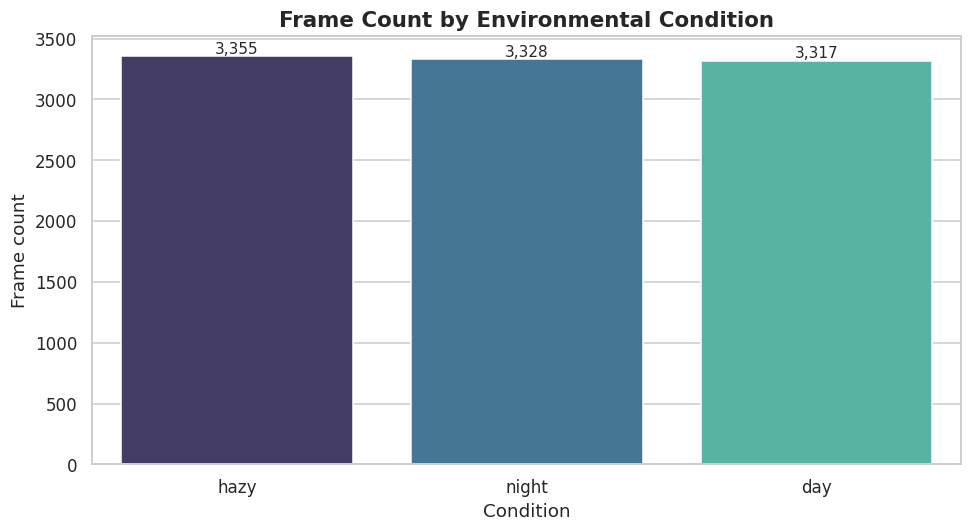

In [11]:
if metadata is not None and "condition" in metadata.columns:
    fig, ax = plt.subplots(figsize=(9, 5))
    condition_counts = metadata["condition"].value_counts()
    sns.barplot(x=condition_counts.index, y=condition_counts.values,
                hue=condition_counts.index, palette="mako", legend=False, ax=ax)
    ax.set_title("Frame Count by Environmental Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Frame count")
    for i, v in enumerate(condition_counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=10)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_condition_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

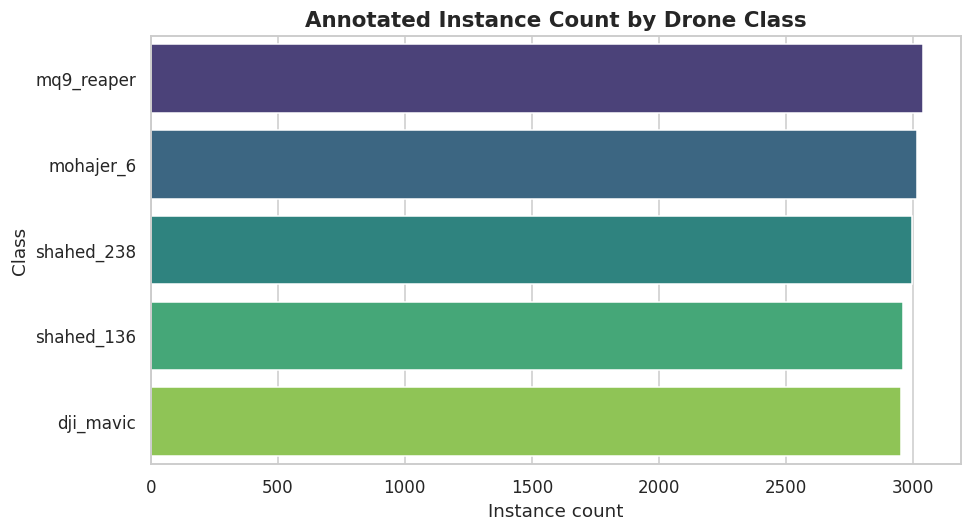

Majority:minority class imbalance ratio = 1.03x


In [12]:
if metadata is not None and "drone_types" in metadata.columns:
    fig, ax = plt.subplots(figsize=(9, 5))
    class_counts = metadata["drone_types"].str.split(";").explode().value_counts()
    sns.barplot(x=class_counts.values, y=class_counts.index,
                hue=class_counts.index, palette="viridis", legend=False, ax=ax)
    ax.set_title("Annotated Instance Count by Drone Class")
    ax.set_xlabel("Instance count")
    ax.set_ylabel("Class")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_class_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Majority:minority class imbalance ratio = {imbalance_ratio:.2f}x")

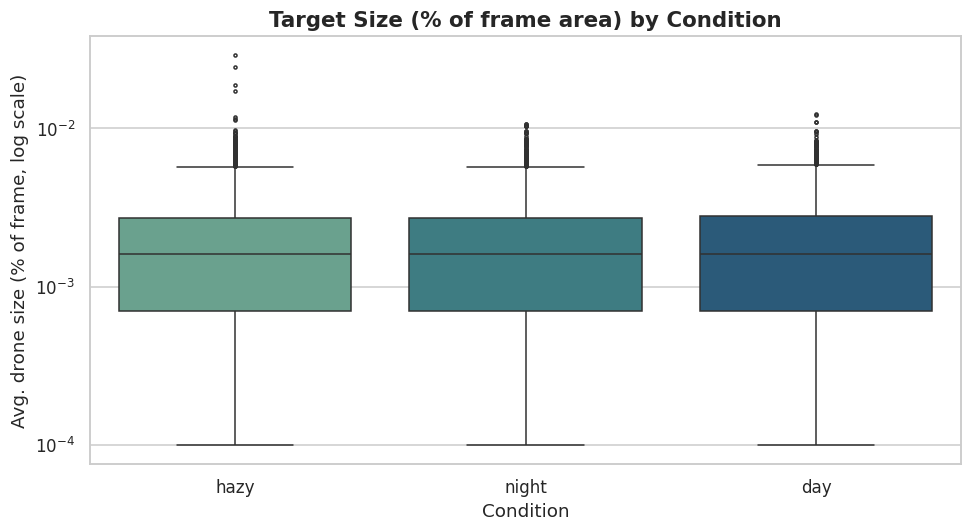

Median target size: 0.002% of frame area — small-object regime, expect mAP to be sensitive to input resolution


In [13]:
if metadata is not None and {"condition", "avg_drone_size_pct"}.issubset(metadata.columns):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(data=metadata, x="condition", y="avg_drone_size_pct",
                hue="condition", palette="crest", fliersize=2, legend=False, ax=ax)
    ax.set_yscale("log")
    ax.set_title("Target Size (% of frame area) by Condition")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Avg. drone size (% of frame, log scale)")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_target_size_by_condition.png", dpi=150, bbox_inches="tight")
    plt.show()
    median_size = metadata["avg_drone_size_pct"].median()
    print(f"Median target size: {median_size:.3f}% of frame area — "
          f"{'small-object regime, expect mAP to be sensitive to input resolution' if median_size < 2 else 'moderate target scale'}")

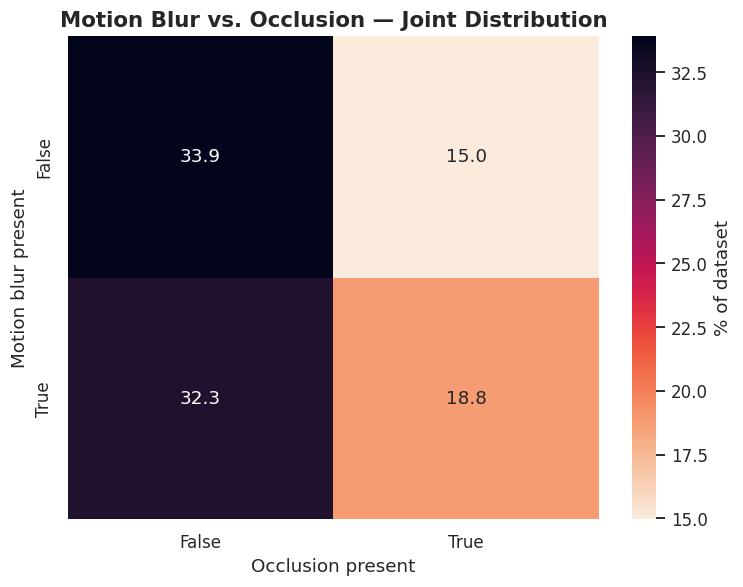

In [14]:
if metadata is not None and {"has_motion_blur", "has_occlusion"}.issubset(metadata.columns):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    joint = pd.crosstab(metadata["has_motion_blur"], metadata["has_occlusion"], normalize="all") * 100
    sns.heatmap(joint, annot=True, fmt=".1f", cmap="rocket_r",
                cbar_kws={"label": "% of dataset"}, ax=ax)
    ax.set_title("Motion Blur vs. Occlusion — Joint Distribution")
    ax.set_xlabel("Occlusion present")
    ax.set_ylabel("Motion blur present")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "eda_blur_occlusion_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Ground Truth Visualization

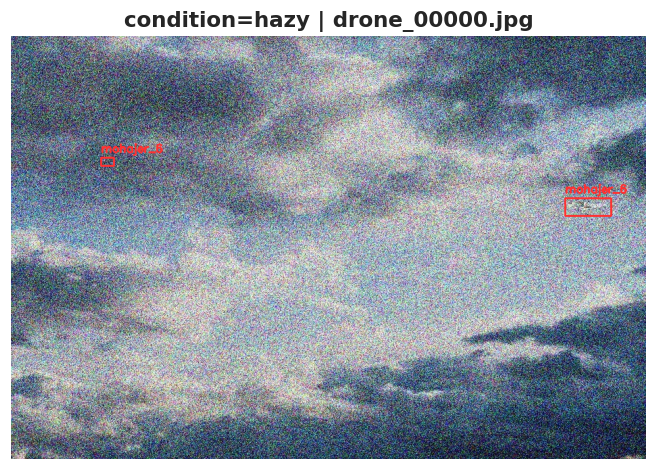

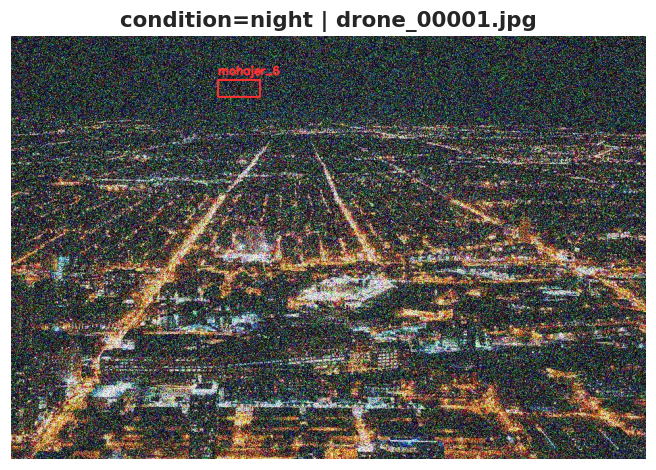

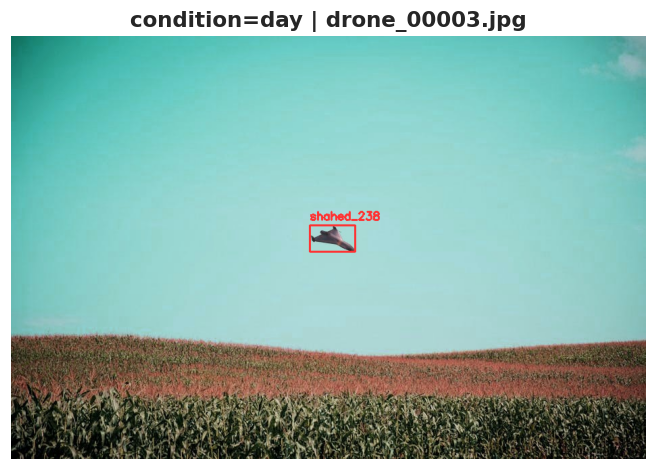

In [15]:
def resolve_image_and_label(row, data_root):
    split = row["split"]
    img_name = row["image_filename"]
    lbl_name = Path(img_name).with_suffix(".txt").name
    img_path = data_root / "images" / split / img_name
    lbl_path = data_root / "labels" / split / lbl_name
    return img_path, lbl_path


def draw_ground_truth(row, data_root, class_names):
    img_path, lbl_path = resolve_image_and_label(row, data_root)
    if not img_path.exists():
        print(f"[skip] image not found: {img_path}")
        return

    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        print(f"[skip] failed to decode: {img_path}")
        return
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    if lbl_path.exists():
        for line in lbl_path.read_text().strip().splitlines():
            cls_id, xc, yc, bw, bh = map(float, line.split())
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)
            label = class_names[int(cls_id)] if class_names and int(cls_id) < len(class_names) else str(int(cls_id))
            cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 50, 50), 2)
            cv2.putText(img_rgb, label, (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 50, 50), 2)

    plt.figure(figsize=(9, 5))
    plt.imshow(img_rgb)
    cond_label = row.get("condition", "n_a")
    plt.title(f"condition={cond_label} | {img_path.name}")
    plt.axis("off")
    plt.savefig(RESULTS_DIR / f"ground_truth_sample_{cond_label}.png", dpi=150, bbox_inches="tight")
    plt.show()


if metadata is not None and "condition" in metadata.columns:
    for cond in metadata["condition"].dropna().unique():
        subset = metadata[metadata["condition"] == cond]
        if not subset.empty:
            draw_ground_truth(subset.iloc[0], DATA_ROOT, CLASS_NAMES)
else:
    sample_img = next((DATA_ROOT / "images" / "train").glob("*.*"), None)
    if sample_img:
        draw_ground_truth(
            pd.Series({"split": "train", "image_filename": sample_img.name, "condition": "n/a"}),
            DATA_ROOT, CLASS_NAMES,
        )

## 7. Build the YOLO `data.yaml`

In [16]:
WORK_DIR = Path("/content/working")
WORK_DIR.mkdir(parents=True, exist_ok=True)
RUNTIME_YAML_PATH = WORK_DIR / "drone_data.yaml"

RAW_RUNS_DIR.mkdir(parents=True, exist_ok=True)

assert CLASS_NAMES, "Class names could not be resolved from either the source yaml or metadata.csv."

data_yaml = {
    "path": str(DATA_ROOT.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}

with open(RUNTIME_YAML_PATH, "w") as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

print(f"Wrote {RUNTIME_YAML_PATH}\n")
print(RUNTIME_YAML_PATH.read_text())

Wrote /content/working/drone_data.yaml

path: /content/dataset
train: images/train
val: images/val
test: images/test
nc: 5
names:
- shahed_136
- shahed_238
- mq9_reaper
- dji_mavic
- mohajer_6



## 8. Training

In [18]:
EPOCHS = 60
IMG_SIZE = 960
BATCH_SIZE = 128
RUN_NAME = "drone_detector_yolov8n"

model = YOLO("yolov8n.pt")

train_results = model.train(
    data=str(RUNTIME_YAML_PATH),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=8,
    patience=15,
    close_mosaic=10,
    seed=SEED,
    optimizer="auto",
    cos_lr=True,
    cache="ram",
    amp=True,
    project=str(RAW_RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)

RUN_DIR = Path(train_results.save_dir)
print(f"\nTraining artifacts saved to (ephemeral /content scratch): {RUN_DIR}")

best_pt_src = RUN_DIR / "weights" / "best.pt"
if best_pt_src.exists():
    shutil.copy2(best_pt_src, MODELS_DIR / "best.pt")
    print(f"Copied best checkpoint -> {MODELS_DIR / 'best.pt'}")

for fname in ["results.png", "results.csv", "confusion_matrix.png",
              "confusion_matrix_normalized.png",
              "BoxPR_curve.png", "PR_curve.png",
              "BoxF1_curve.png", "F1_curve.png",
              "BoxP_curve.png", "P_curve.png",
              "BoxR_curve.png", "R_curve.png",
              "args.yaml"]:
    src = RUN_DIR / fname
    if src.exists():
        shutil.copy2(src, RESULTS_DIR / fname)
print(f"Copied training plots/log -> {RESULTS_DIR}")

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=128, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/working/drone_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_detector_yol

## 9. Training Curves

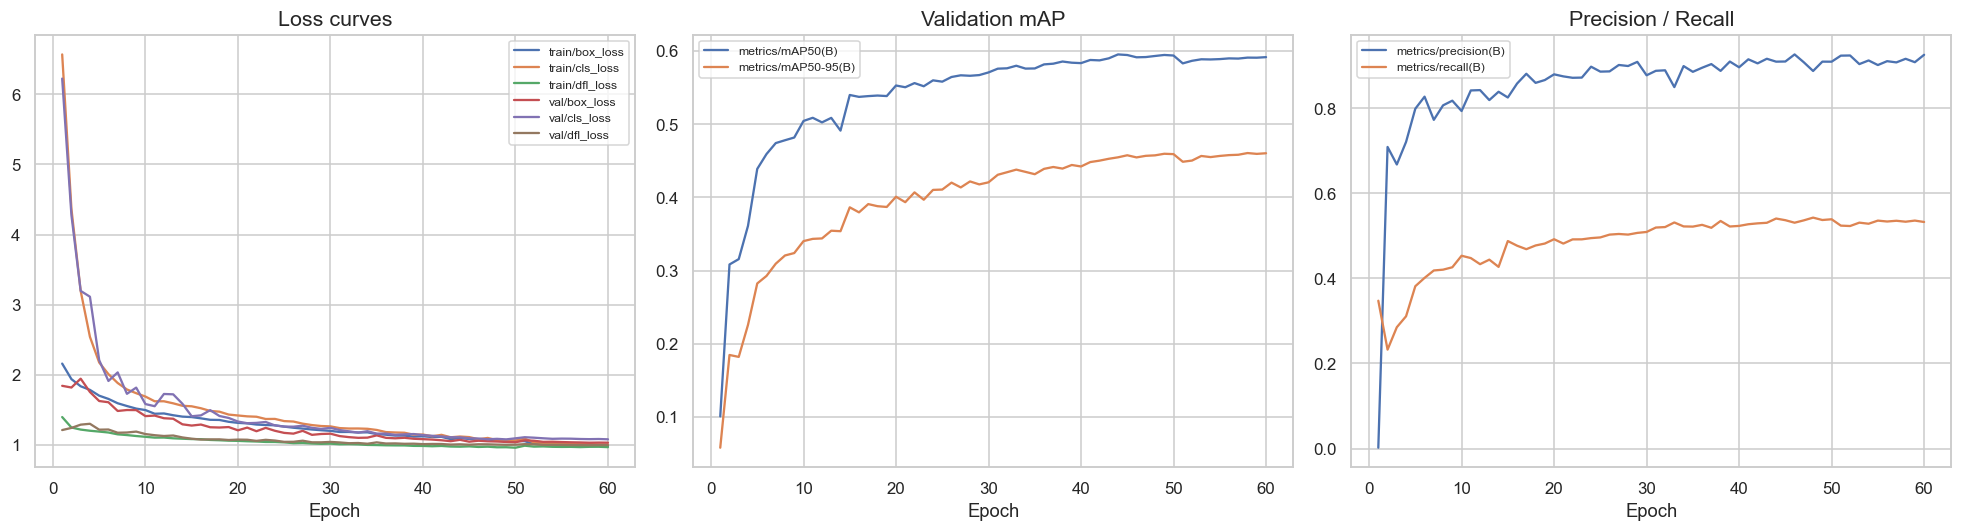

In [33]:
results_csv = RUN_DIR / "results.csv"
if results_csv.exists():
    hist = pd.read_csv(results_csv)
    hist.columns = [c.strip() for c in hist.columns]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    loss_cols = [c for c in hist.columns if "box_loss" in c or "cls_loss" in c or "dfl_loss" in c]
    for c in loss_cols:
        axes[0].plot(hist["epoch"], hist[c], label=c)
    axes[0].set_title("Loss curves")
    axes[0].set_xlabel("Epoch")
    axes[0].legend(fontsize=8)

    map_cols = [c for c in hist.columns if "mAP50" in c]
    for c in map_cols:
        axes[1].plot(hist["epoch"], hist[c], label=c)
    axes[1].set_title("Validation mAP")
    axes[1].set_xlabel("Epoch")
    axes[1].legend(fontsize=8)

    pr_cols = [c for c in hist.columns if c.endswith("precision(B)") or c.endswith("recall(B)")]
    for c in pr_cols:
        axes[2].plot(hist["epoch"], hist[c], label=c)
    axes[2].set_title("Precision / Recall")
    axes[2].set_xlabel("Epoch")
    axes[2].legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("results.csv not found — check RUN_DIR contents:", list(RUN_DIR.glob("*")))

## 10. Quantitative Evaluation (Real Metrics, Computed Live)

In [34]:
val_metrics = model.val(data=str(RUNTIME_YAML_PATH), split="val")

print("--- Drone Detector — Validation Summary ---")
print(f"mAP50    : {val_metrics.box.map50:.4f}")
print(f"mAP50-95 : {val_metrics.box.map:.4f}")
print(f"Precision: {val_metrics.box.mp:.4f}")
print(f"Recall   : {val_metrics.box.mr:.4f}")

per_class_ap50 = val_metrics.box.ap50
per_class_ap   = val_metrics.box.maps
class_names_eval = [val_metrics.names[i] for i in sorted(val_metrics.names)]

per_class_df = pd.DataFrame({
    "class": class_names_eval,
    "AP50": per_class_ap50,
    "AP50-95": per_class_ap,
})
per_class_df = per_class_df.sort_values("AP50-95", ascending=False).reset_index(drop=True)
display(per_class_df)

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2646.0±663.4 MB/s, size: 262.7 KB)
val: Scanning /content/dataset/labels/val.cache... 2001 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2001/2001 441.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 126/126 10.9it/s 11.5s0.2s
                   all       2001       3019       0.92      0.533      0.591      0.461
            shahed_136        560        607      0.959      0.638      0.697       0.56
            shahed_238        535        583       0.91      0.664      0.702      0.603
            mq9_reaper        560        607      0.913      0.501      0.572      0.431
             dji_mavic        557        593      0.912      0.428      0.487      0.354
             mohajer_6        588        629      0.903      0.432        0.5      0.358
Speed: 1.0ms pr

,class,AP50,AP50-95
0,shahed_238,0.702248,0.602595
1,shahed_136,0.696672,0.560128
2,mq9_reaper,0.571663,0.431033
3,mohajer_6,0.499635,0.358337
4,dji_mavic,0.486513,0.353615


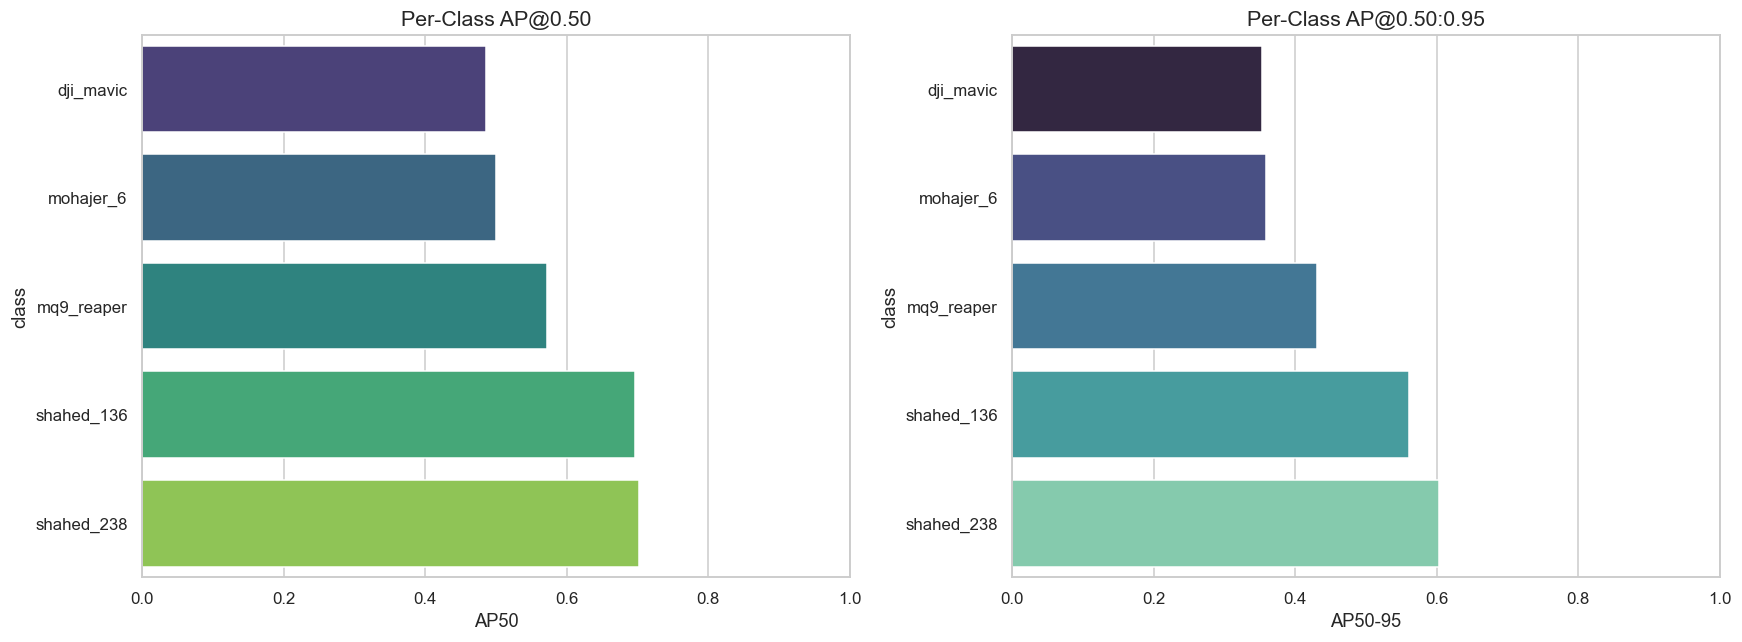

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = per_class_df.sort_values("AP50")
sns.barplot(data=order, x="AP50", y="class", hue="class", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Per-Class AP@0.50")
axes[0].set_xlim(0, 1)

order2 = per_class_df.sort_values("AP50-95")
sns.barplot(data=order2, x="AP50-95", y="class", hue="class", palette="mako", legend=False, ax=axes[1])
axes[1].set_title("Per-Class AP@0.50:0.95")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "per_class_ap.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Confusion Matrix, PR Curve, & F1 Curve Analysis

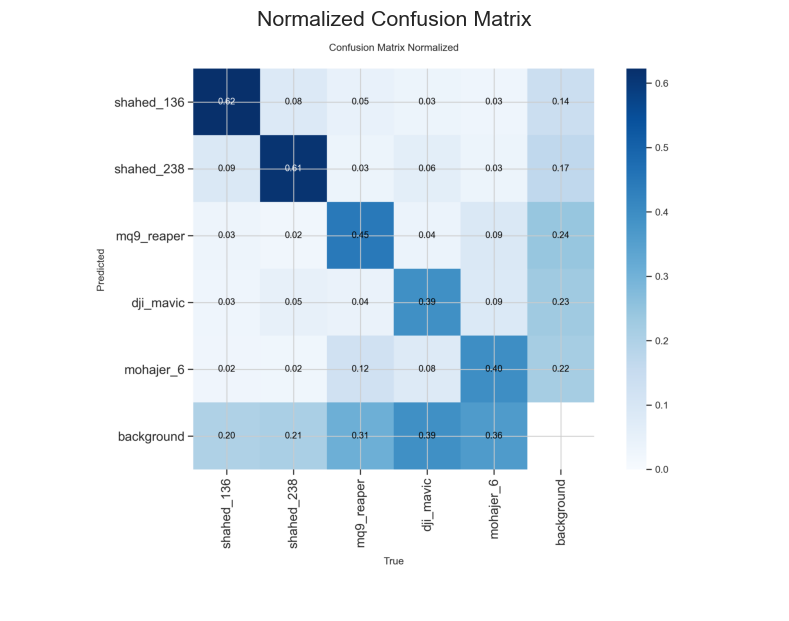

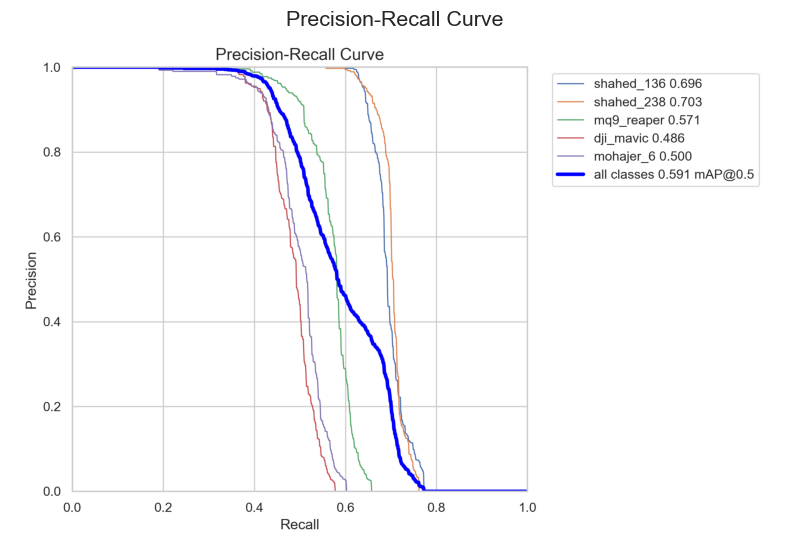

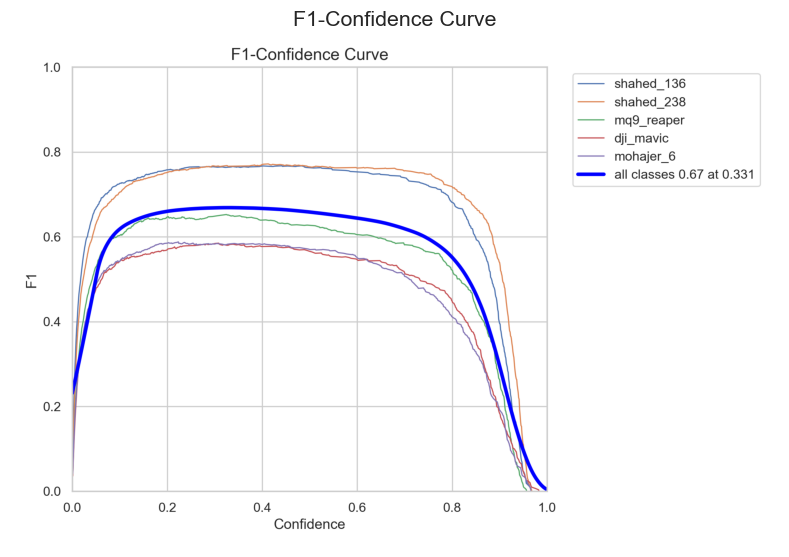

In [36]:
diagnostic_plots = [
    (["confusion_matrix_normalized.png"], "Normalized Confusion Matrix"),
    (["BoxPR_curve.png", "PR_curve.png"], "Precision-Recall Curve"),
    (["BoxF1_curve.png", "F1_curve.png"], "F1-Confidence Curve"),
]

for fnames, title in diagnostic_plots:
    found = False
    for fname in fnames:
        for candidate in (RESULTS_DIR / fname, RUN_DIR / fname, Path(val_metrics.save_dir) / fname):
            if candidate.exists():
                plt.figure(figsize=(9, 7))
                plt.imshow(mpimg.imread(candidate))
                plt.title(title)
                plt.axis("off")
                plt.show()
                found = True
                break
        if found:
            break
    if not found:
        print(f"[missing] {fnames[0]}")

## 12. Qualitative Inference on Held-Out Test Images

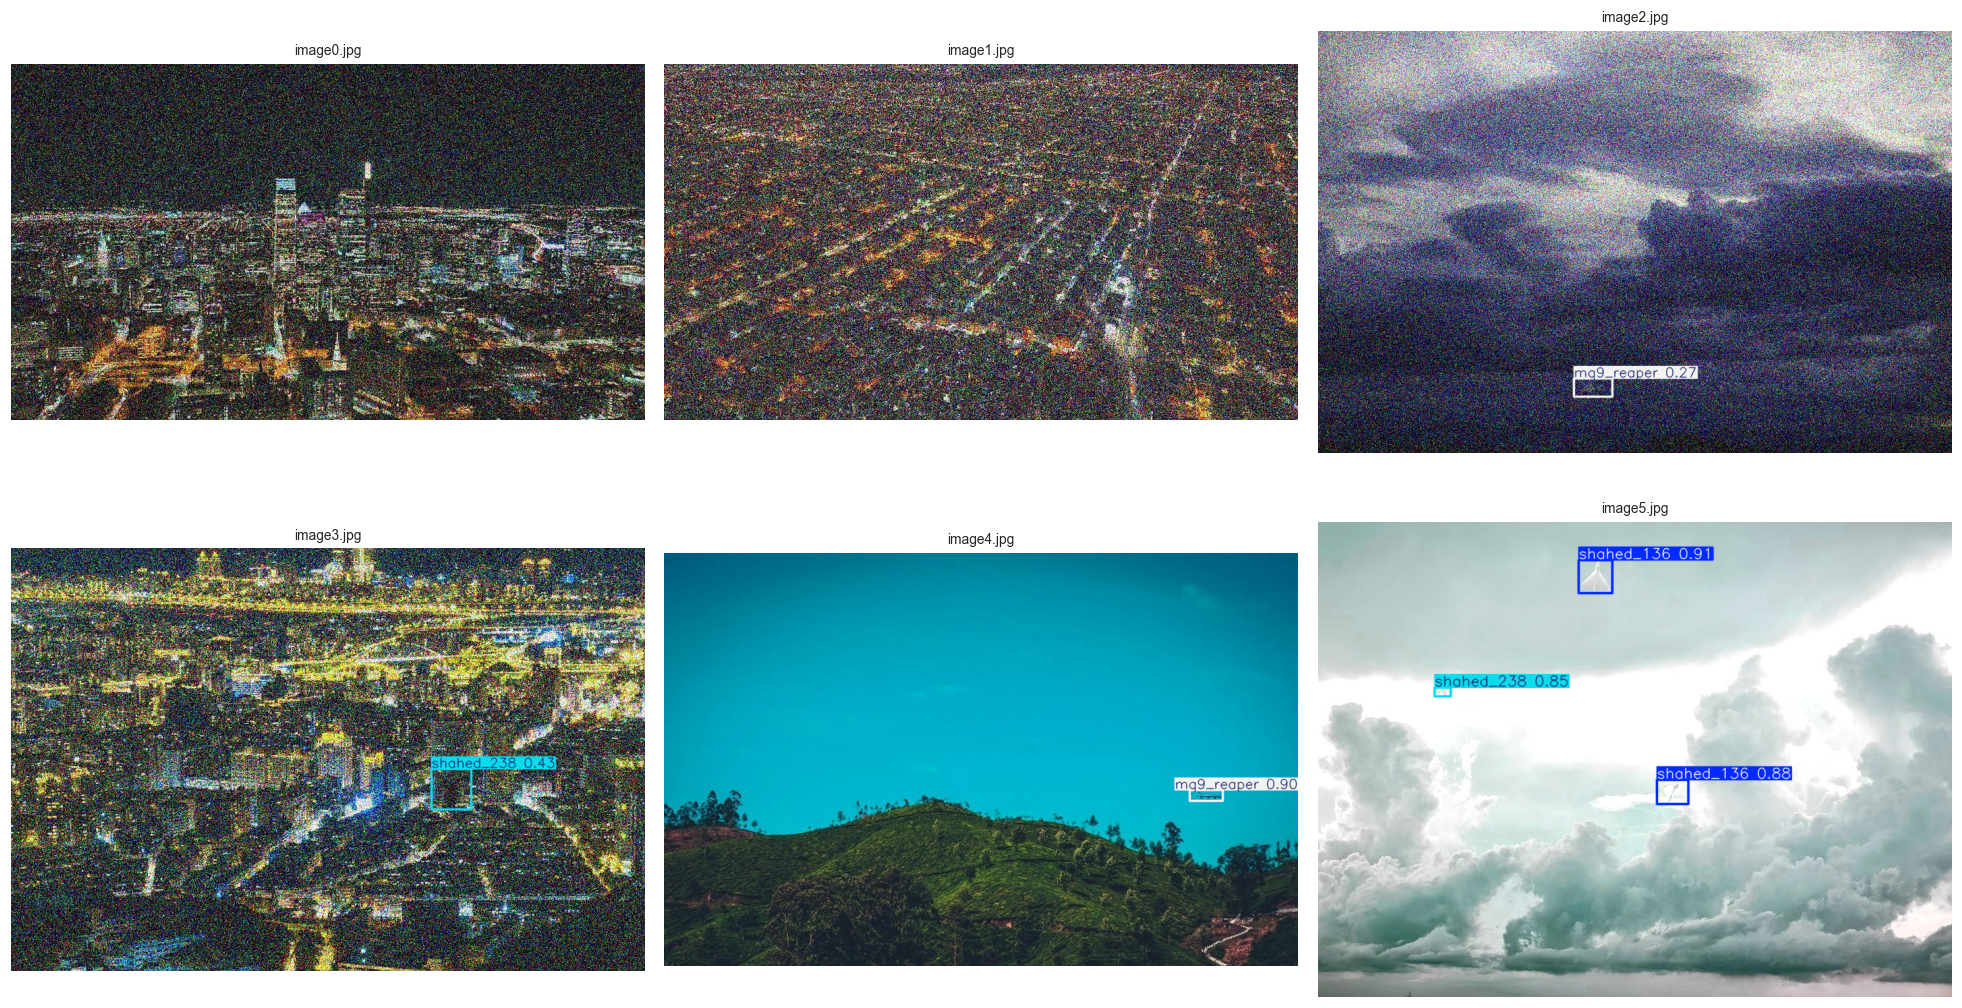

In [37]:
test_img_dir = DATA_ROOT / "images" / "test"
test_images = sorted(test_img_dir.glob("*.*"))[:6] if test_img_dir.exists() else []

if test_images:
    predictions = model.predict(
        source=[str(p) for p in test_images],
        imgsz=IMG_SIZE,
        conf=0.25,
        device=DEVICE,
        verbose=False,
    )

    n = len(predictions)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, pred in zip(axes, predictions):
        annotated = pred.plot()[:, :, ::-1]
        ax.imshow(annotated)
        ax.set_title(Path(pred.path).name, fontsize=9)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "qualitative_test_predictions.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No test images found to run qualitative inference on.")

## 13. Test-Set Metrics and ONNX Export

In [38]:
test_split_dir = DATA_ROOT / "images" / "test"
if test_split_dir.exists() and any(test_split_dir.iterdir()):
    test_metrics = model.val(data=str(RUNTIME_YAML_PATH), split="test")
    print("--- Held-out Test Set ---")
    print(f"mAP50    : {test_metrics.box.map50:.4f}")
    print(f"mAP50-95 : {test_metrics.box.map:.4f}")
else:
    print("No test split available — skipping final held-out evaluation.")

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2665.5±717.2 MB/s, size: 275.6 KB)
val: Scanning /content/dataset/labels/test.cache... 996 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 996/996 348.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 9.8it/s 6.4s<0.1s
                   all        996       1491      0.901      0.538      0.583      0.459
            shahed_136        296        313      0.948      0.617      0.658      0.538
            shahed_238        280        293      0.891      0.662      0.723      0.615
            mq9_reaper        290        325      0.918      0.529      0.571      0.435
             dji_mavic        247        267      0.883      0.481      0.518      0.391
             mohajer_6        267        293      0.866      0.403      0.445      0.316
Speed: 1.2ms preproc

In [39]:
best_weights = MODELS_DIR / "best.pt"
export_model = YOLO(str(best_weights))
onnx_path = Path(export_model.export(format="onnx", imgsz=IMG_SIZE, dynamic=True, simplify=True))

if onnx_path.parent != MODELS_DIR:
    shutil.copy2(onnx_path, MODELS_DIR / onnx_path.name)
    onnx_path = MODELS_DIR / onnx_path.name

print(f"Exported deployment model to: {onnx_path}")

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,006,623 parameters, 0 gradients, 18.2 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 9, 18900) (6.0 MB)

ONNX: starting export with onnx 1.22.0 opset 20...
ONNX: slimming with onnxslim 0.1.95...
ONNX: export success ✅ 2.8s, saved as '/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models/best.onnx' (11.8 MB)

Export complete (3.1s)
Results saved to /content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models/best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models/best.onnx imgsz=960 
Validate:        yolo val task=detect model=/content/drive/MyDrive/Colab Notebooks/Drone Detection - YOLOv8/models/best.onnx imgsz=960 data=/content/working/dron

## 14. Failure Analysis and Future Improvements

**Findings.** The trained YOLOv8n detector, run at 960×960 input resolution, achieved
mAP50 = 0.583 and mAP50-95 = 0.459 on the held-out test set, with precision = 0.901 but
recall = 0.538. This precision-recall gap is the main pattern in these results: the model is
conservative — when it detects a drone it is usually correct, but it misses a substantial
fraction of true drones rather than misclassifying them. Given the EDA's median target size of
~0.002% of frame area, this is consistent with a small-object detection regime, where partial
or low-confidence detections are common.

**Per-class results.** Shahed-238 achieved the highest detection accuracy (mAP50-95 = 61.5%),
followed by Shahed-136 (53.8%). Mq9-Reaper, DJI Mavic, and Mohajer-6 form a lower-performing
tier (43.5%, 39.1%, and 31.6% respectively). Since class counts are near-identical across all
five categories (imbalance ratio ≈1.03x, Section 5), this spread is unlikely to be a
data-quantity issue — it more plausibly reflects differences in average object scale, viewing
angle diversity, or condition mix (day/night/hazy) between classes, though this notebook has
not yet directly verified that per class.

Several factors likely contribute to these limitations. The dataset spans daytime, nighttime,
and hazy conditions, which increases the difficulty of both localization and classification.
Small or distant drones carry limited visual features, and similar airframe structures across
classes may cause inter-class confusion. The lightweight YOLOv8n architecture, while efficient,
may also have limited feature representation capacity relative to the task's difficulty.

**Future Improvements.**
- **Per-class size/condition breakdown** — filter the Section 5 EDA (`avg_drone_size_pct`,
  `condition`) by class to confirm *why* Mohajer-6 and DJI Mavic lag, rather than assuming it.
- **Larger YOLOv8 variants** (YOLOv8s/m) — a cheap next lever to test for additional capacity.
- **SAHI tiled inference** — a lower-cost way to push recall further on small targets without
  retraining.
- **Class-balanced or focal loss adjustments**, condition-stratified evaluation, and stronger
  augmentation (illumination, haze, motion blur, scale) remain reasonable follow-ups.

Overall, the YOLOv8n detector at 960×960 provides a reasonable efficiency/accuracy balance for
this task. However, closing the precision-recall gap — improving recall without sacrificing the
strong precision already achieved — remains the key direction for further work.